# VoltTrust Tunisia: Phase 1 baseline detector

Implements the Goal 1 strategy on the Phase 1 dataset:

- **L1 physics and rules**: voltage-profile model per meter (fitted on the train split), power identity,
  register consistency, stuck values, dropouts (not collection gaps), meter tamper alarms, feeder-phase
  energy balance (an alert on the phase, with a regression ranking the homes to check),
  head-meter events (outage, phase loss, sag, MV voltage step, frequency), transformer overload from
  an estimated top-oil temperature (and the oil residual where a monitor is fitted), rooftop panel checks.
- **L2**: Isolation Forest on the physics residuals, with SHAP naming the signal behind each forest
  alert; persistent-offset test on the voltage residual (bias vs drift by its slope).
- **L3**: a rule table that gives every alert a verdict, *grid_event*, *equipment_fault* or *data_quality*.

Thresholds were set on the **val** split. Training uses the **train** split (January to April, no data
problems). The **test** split contains two attack types never seen before (replay, coordinated false data).

This notebook runs the default equipment (`Site()`): the substation concentrator's metering, STEG's phase
map, no oil monitor, inverter readings from the 3 opt-in solar homes and the net meter for the other 11.
Load profiles arrive every 12 hours, so "time to operator" includes that wait; alarms arrive at once.

In [1]:
import sys, json, glob
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt

# Works from the repo (notebooks/) and on Kaggle (the VoltTrust dataset attached under /kaggle/input)
cands = [Path("../data"), Path("data")] + [Path(p).parent for p in glob.glob("/kaggle/input/**/data/events.csv", recursive=True)]
DATA = next(p for p in cands if (p / "events.csv").exists())
for p in [Path("../src"), Path("src")] + [Path(p).parent for p in glob.glob("/kaggle/input/**/src/volttrust", recursive=True)]:
    if p.exists(): sys.path.insert(0, str(p.resolve()))

# Reference categorical palette (fixed order), recessive grid
C = {"blue": "#2a78d6", "orange": "#eb6834", "aqua": "#1baf7a", "yellow": "#eda100", "gray": "#8a8a85"}
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.6,
                     "axes.edgecolor": "#b0afa8", "lines.linewidth": 1.6, "font.size": 9,
                     "axes.titlesize": 10, "axes.titleweight": "bold", "legend.frameon": False})
print("data:", DATA)

data: ../data


In [2]:
import time
from volttrust.detect import features, detectors, evaluate, calibrate
t0 = time.perf_counter()
D = features.load(DATA)
R = features.residuals(D)
det = detectors.detect(D, R)
print(f"detector ran on {D.T} intervals x {D.H} meters in {time.perf_counter() - t0:.1f} s")
events = pd.read_csv(DATA / "events.csv")
meter_phase = {m: f"F{f + 1}-{'ABC'[p]}" for m, f, p in zip(D.meters, D.feeder, D.phase)}
res, al = evaluate.match(det.alerts, events, D.idx, meter_phase, collected=D.collected, meters=D.meters)
point = evaluate.point_metrics(det.meter_rule, DATA / "meters.parquet", D.meters, D.idx, D.split)
summary = evaluate.summarize(res, al, D.idx, D.split, point)
pd.DataFrame(summary).T

/usr/local/lib/python3.13/dist-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


 19%|====                | 38/199 [00:11<00:46]       

 21%|====                | 42/199 [00:12<00:44]       

 22%|====                | 44/199 [00:13<00:45]       

 24%|=====               | 48/199 [00:14<00:44]       

...

 96%|=================== | 191/199 [00:57<00:02]       

 98%|===================| 195/199 [00:58<00:01]       

 99%|===================| 197/199 [00:59<00:00]       

detector ran on 35040 intervals x 48 meters in 101.4 s


,events,event_recall,event_recall_physical,event_recall_data_problems,verdict_accuracy_on_detected,events_hidden_by_collection_gap,event_recall_observable,alerts,alert_precision,false_alerts_per_day,false_alerts_per_feeder_per_day,median_time_to_detect_h,median_time_to_operator_h,median_time_to_operator_h_physical,energy_gap_alerts,events_with_energy_gap_alert,suspect_top3_hit_rate,row_precision,row_recall,row_false_positive_rate
val,92.0,0.924,0.895,0.932,0.988,5.0,0.977,577.0,0.969,0.2,0.10,0.0,8.75,9.50,67.0,30.0,0.700,0.971,0.394,0.00360
test,102.0,0.912,0.957,0.899,0.989,4.0,0.949,659.0,0.977,0.1,0.05,0.0,7.75,8.38,46.0,21.0,0.762,0.970,0.464,0.00231


## Against the proposal targets

Targets: recall of at least 0.90, at most 1 false alert per feeder per day, at least 0.85 correct
verdicts; processing under 1 s, alarms under 5 minutes, other checks within one 12-hour batch.
Some events fall entirely inside readings the concentrator failed to collect; `event_recall_observable`
leaves those out.

In [3]:
cols = ["event_recall", "event_recall_observable", "verdict_accuracy_on_detected", "false_alerts_per_feeder_per_day",
        "median_time_to_detect_h", "median_time_to_operator_h"]
pd.DataFrame({sp: {k: summary[sp][k] for k in cols} for sp in ("val", "test")})

,val,test
event_recall,0.924,0.912
event_recall_observable,0.977,0.949
verdict_accuracy_on_detected,0.988,0.989
false_alerts_per_feeder_per_day,0.100,0.050
median_time_to_detect_h,0.000,0.000
median_time_to_operator_h,8.750,7.750


## Recall and verdict accuracy by anomaly type (val + test)

In [4]:
pt = evaluate.per_type(res)
pt

,family,anomaly_type,events,recall,verdict_acc,held_out,median_ttd_h,median_to_operator_h,suspect_top3_hit_rate
0,biased_reading,bias_ct_gain,6,0.833,1.000,False,189.750,194.750,1.000
1,biased_reading,bias_voltage,6,1.000,1.000,False,1.750,10.250,NaN
2,biased_reading,clock_skew,6,1.000,0.833,False,0.875,10.875,0.750
3,corrupted_reading,dropout,25,1.000,1.000,False,0.000,5.500,1.000
4,corrupted_reading,spike,40,0.775,1.000,False,0.000,3.250,NaN
5,degraded_sensor,drift_current,8,0.875,1.000,False,128.000,129.000,0.714
6,degraded_sensor,drift_voltage,8,1.000,1.000,False,47.375,52.875,1.000
7,degraded_sensor,noise_growth,6,0.833,1.000,False,1.250,10.000,0.333
8,degraded_sensor,pv_reading_stuck,4,1.000,1.000,False,0.000,1.625,NaN
9,degraded_sensor,stuck,15,1.000,1.000,False,0.000,6.500,0.111


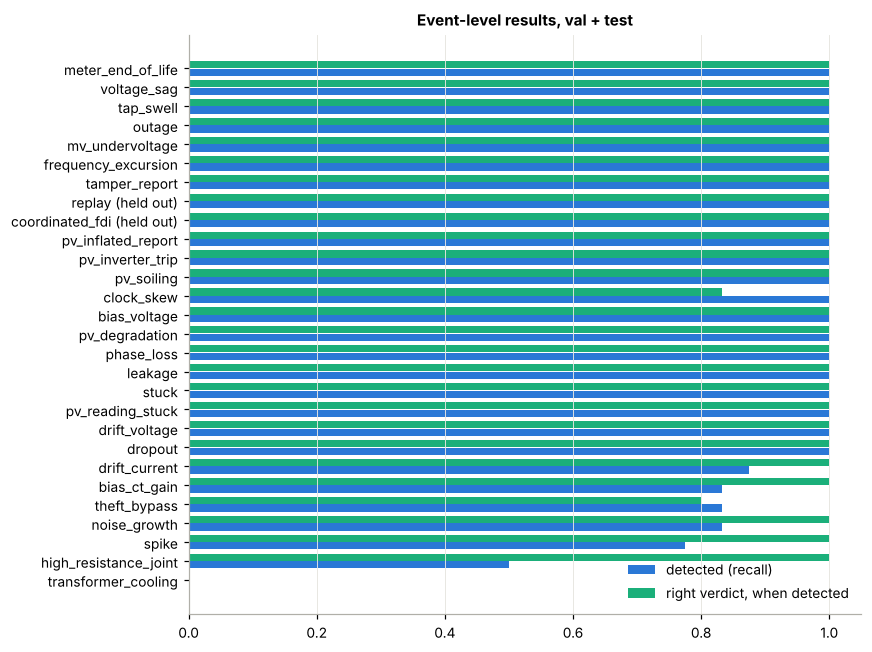

In [5]:
pt2 = pt.sort_values("recall")
fig, ax = plt.subplots(figsize=(8, 6))
y = np.arange(len(pt2))
ax.barh(y - 0.2, pt2.recall, height=0.38, color=C["blue"], label="detected (recall)")
ax.barh(y + 0.2, pt2.verdict_acc.fillna(0), height=0.38, color=C["aqua"], label="right verdict, when detected")
ax.set_yticks(y, [f"{t}{' (held out)' if h else ''}" for t, h in zip(pt2.anomaly_type, pt2.held_out)])
ax.set_xlim(0, 1.05); ax.legend(loc="lower right"); ax.set_title("Event-level results, val + test")
ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()

## Rooftop panels: inverter homes vs estimated homes

The 3 opt-in homes are checked on their inverter reading; the other 11 on an estimate from the net
meter and the neighborhood's reference panel. A frozen or inflated inverter reading can only exist where
there is an inverter reading, so those two types are only on opt-in homes.

In [6]:
evaluate.by_pv_source(res, al, D)

,pv_source,homes,events,recall,recall_panel_faults,verdict_acc,panel_alerts,false_panel_alerts,false_per_home_per_year
0,inverter_optin,3,9,1.0,1.0,1.0,21,0,0.00
1,estimated,11,9,1.0,1.0,1.0,61,22,2.98


## Confidence: measured per rule

Each alert's confidence is how often its rule gave the right verdict in May to Jul, pulled toward the
hand-set value (worth 10 alerts) and capped at 0.97. Alerts where 2 or more rules agree have their own
value. Calibration error (ECE) is the average gap between stated confidence and how often alerts are
right, before (hand-set) and after (measured), on the test months.

In [7]:
cal = calibrate.fit(al, res, D.split, "val", D.idx, source="data")
al = calibrate.apply(al, cal)
ece, per_rule = calibrate.report(al, res, D.split, ("test",))
print(ece)
per_rule.sort_values("alerts", ascending=False).head(12)

{'alerts': 659, 'share_right': 0.95, 'ece_before': 0.149, 'ece_after': 0.075}


,rule,cell,alerts,observed,stated_before,stated_after
5,dropout,single,74,1.000,0.990,0.970
16,iforest,agree,57,1.000,0.526,0.744
13,head_outage,single,45,1.000,0.950,0.901
36,voltage_offset,single,43,1.000,0.700,0.921
17,iforest,single,40,1.000,0.500,0.910
12,head_mv_step,single,37,0.973,0.850,0.820
21,power_identity,single,35,1.000,0.850,0.970
15,head_sag,single,30,1.000,0.900,0.964
22,power_identity_persist,agree,28,1.000,0.925,0.970
9,group_voltage_rise,single,26,0.577,0.800,0.727


## Why the Isolation Forest flagged a reading: SHAP

Forest alerts only say "unusual pattern". SHAP splits the forest's score at the alert's peak reading into
the push from each of its 4 signals: the voltage gap to the physics model (`r_v`), how jumpy that gap is
over 2 hours (`rv_sd`), the power-identity residual (`r_id`) and the register residual (`r_reg`).
Positive means "pushed toward unusual".

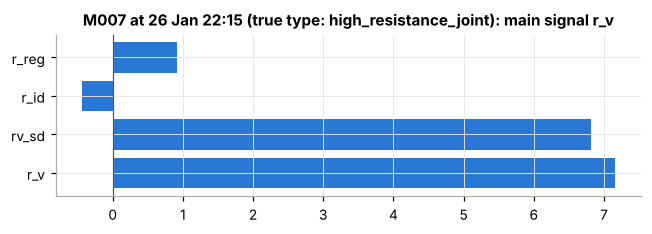

SHAP time: {'forest_alerts': 199, 'shap_seconds_total': 64.31, 'shap_ms_per_alert': 323.2}


In [8]:
fa = al[al.rule == "iforest"]
ex = fa[fa.matched_event.notna()].iloc[0]
etype = events.set_index("event_id").anomaly_type.get(ex.matched_event)
fig, ax = plt.subplots(figsize=(6, 2.2))
ax.barh(list(ex.shap), list(ex.shap.values()), color=C["blue"])
ax.set_title(f"{ex.asset} at {ex.t_start:%d %b %H:%M} (true type: {etype}): main signal {ex.shap_top['feature']}")
ax.axvline(0, color="#55554f", lw=0.8); plt.tight_layout(); plt.show()
print("SHAP time:", {k: v for k, v in det.timing.items()})

In [9]:
# the main signal per forest alert, by the true anomaly type it matched (a first check that explanations are right)
ev_type = dict(zip(res.event_id, res.anomaly_type))
pd.crosstab(fa.matched_event.map(ev_type).fillna("no event (false alert)"),
            fa.shap_top.map(lambda x: x["feature"]), rownames=["true type"], colnames=["main signal"])

main signal,r_v,rv_sd
true type,,
clock_skew,0,7
coordinated_fdi,0,5
high_resistance_joint,8,30
meter_end_of_life,0,3
noise_growth,3,142
replay,0,1


## Explanation quality: the four measures against their targets

Scored against the injected ground truth, on both seeds and on the val and test months:
verdict accuracy, the right home among the 3 to check for energy gaps, calibration error (ECE) and
whether SHAP's main signal is the signal the injected fault corrupts, both raw and as shown to the
operator (a pattern alert leads with a nearby voltage rule's reason, SHAP second). Built by
`python -m volttrust.detect.quality` into `results/explanation_quality.csv`. Seed 42's val ECE is
in-sample (the confidence table was fitted on those months); seed 2026 uses seed 42's table.

In [10]:
q = pd.read_csv(DATA.parent / "results" / "explanation_quality.csv")
tab = q[q.fault_type == "all"].pivot_table(index=["measure", "target"], columns=["seed", "window"],
                                            values="value", aggfunc="first")
tab.loc[[("verdict_accuracy", ">= 0.85"), ("right_home_in_top3", ">= 0.7"),
         ("calibration_error_ece", "<= 0.08"), ("shap_main_signal_match", ">= 0.8"),
         ("shap_main_signal_match_as_shown", ">= 0.8")]]

seed                                      42            2026       
window                                    test    val   test    val
measure                         target                             
verdict_accuracy                >= 0.85  0.989  0.988  0.980  0.988
right_home_in_top3              >= 0.7   0.762  0.700  0.760  0.737
calibration_error_ece           <= 0.08  0.075  0.049  0.054  0.054
shap_main_signal_match          >= 0.8   0.933  0.969  0.761  0.982
shap_main_signal_match_as_shown >= 0.8   0.944  0.969  0.912  0.982

In [11]:
# SHAP match per fault type, so the dominant noise type can't hide weak ones
q[(q.measure == "shap_main_signal_match") & (q.fault_type != "all")][
    ["seed", "window", "fault_type", "n", "value", "note"]]

,seed,window,fault_type,n,value,note
5,42,val,clock_skew,1,NaN,"no expected signal: reported, left out of the ..."
7,42,val,high_resistance_joint,1,1.000,expected r_v; got r_v 1
9,42,val,meter_end_of_life,1,1.000,expected rv_sd; got rv_sd 1
11,42,val,noise_growth,62,0.968,"expected rv_sd; got rv_sd 60, r_v 2"
18,42,test,clock_skew,6,NaN,"no expected signal: reported, left out of the ..."
20,42,test,coordinated_fdi,5,0.000,expected r_v; got rv_sd 5
22,42,test,meter_end_of_life,2,1.000,expected rv_sd; got rv_sd 2
24,42,test,noise_growth,83,0.988,"expected rv_sd; got rv_sd 82, r_v 1"
26,42,test,replay,1,NaN,"no expected signal: reported, left out of the ..."
33,2026,val,clock_skew,52,NaN,"no expected signal: reported, left out of the ..."


## Grid event or data problem? Verdict confusion (events)

In [12]:
evaluate.confusion(res)

pred_verdict,data_quality,equipment_fault,grid_event,missed
verdict,,,,
data_quality,137,0,2,13
equipment_fault,0,18,0,3
grid_event,0,0,21,0


## From alert to verdict to escalation

Each alert becomes a verdict record and goes through the
escalation router (`escalation/`). Confidence here is the measured value per rule
above; Phase 2 replaces it with the calibrated two-stage confidence model.

In [13]:
sys.path.insert(0, str((DATA.parent / "escalation").resolve()))
from router import Router, Event, TIERS

TEMPLATES = {
    "grid_event": "Likely real {subtype} on {asset}: seen at the feeder head, so the sensors agree with each other.",
    "equipment_fault": "Likely equipment fault ({subtype}) at {asset}: readings are physically consistent but the network behaves abnormally.",
    "data_quality": "Likely data problem ({subtype}) at meter {asset}: {why}",
}
WHY = {
    "voltage_offset": "its voltage is {v:.1f} V away from what the feeder physics predicts, while its neighbours agree with the model.",
    "power_identity_persist": "reported power no longer equals voltage x current x power factor.",
    "group_voltage_rise": "several meters on the feeder report the same voltage rise that the feeder head does not see.",
}

def explain(a):
    if a.rule in detectors.PHASE_RULES:
        # the system names no home: it hands a person the list of homes to check
        homes = ", ".join(f"{x['meter']}" + ("" if x["evidence"] == "strong" else " (weak)") for x in a.suspects)
        where = f"feeder {a.asset[1]}" + (f" phase {a.asset[-1]}" if "-" in a.asset else "")
        return (f"About {abs(a.gap_kw):.2f} kW is {'missing' if a.gap_kw > 0 else 'over-reported'} on "
                f"{where}; homes to check: {homes or 'none stands out'}.")
    why = WHY.get(a.rule, "rules fired: " + ", ".join(a.rules_fired) + ".")
    why = why.format(v=getattr(a, "max_abs_voltage_resid_v", 0) or 0, b=getattr(a, "balance_beta", 0) or 0)
    return TEMPLATES[a.verdict].format(subtype=a.subtype.replace("_", " "), asset=a.asset, why=why)

router = Router(DATA.parent / "escalation" / "policy.yaml")
test_al = al[(al.t_start >= "2025-08-01") & al.matched_event.notna()]
picks = pd.concat([test_al[test_al.rule == r].head(1) for r in
                   ["head_sag", "head_outage", "group_voltage_drop", "voltage_offset", "balance_gap_phase",
                    "power_identity_persist", "group_voltage_rise", "stuck"]])
rows = []
for rec, a in zip(detectors.to_verdict_records(picks), picks.itertuples()):
    d = router.route(Event.from_verdict(rec, meters_on_feeder=24))
    rows.append({"asset": a.asset, "verdict": a.verdict, "subtype": a.subtype, "confidence": a.confidence,
                 "tier": f"{d.tier}: {TIERS[d.tier]}", "explanation": explain(a)})
pd.set_option("display.max_colwidth", 200)
print("decision log intact:", router.verify_log())
pd.DataFrame(rows)

decision log intact: True


,asset,verdict,subtype,confidence,tier,explanation
0,F2-C,grid_event,sag,0.964,T3: human approval required,"Likely real sag on F2-C: seen at the feeder head, so the sensors agree with each other."
1,F1-B,grid_event,outage,0.901,T3: human approval required,"Likely real outage on F1-B: seen at the feeder head, so the sensors agree with each other."
2,M042,equipment_fault,high_resistance_joint,0.614,T3: human approval required,Likely equipment fault (high resistance joint) at M042: readings are physically consistent but the network behaves abnormally.
3,M031,data_quality,drift,0.836,"T2: auto-act + notify, undoable","Likely data problem (drift) at meter M031: its voltage is 0.0 V away from what the feeder physics predicts, while its neighbours agree with the model."
4,F1-B,data_quality,energy_gap,0.818,T3: human approval required,"About 0.11 kW is missing on feeder 1 phase B; homes to check: M010 (weak), M007 (weak), M022 (weak)."
5,M018,data_quality,tampering,0.970,T3: human approval required,Likely data problem (tampering) at meter M018: reported power no longer equals voltage x current x power factor.
6,M030,data_quality,falsified,0.867,T3: human approval required,Likely data problem (falsified) at meter M030: several meters on the feeder report the same voltage rise that the feeder head does not see.
7,M011,data_quality,stuck,0.970,"T1: auto-act, logged","Likely data problem (stuck) at meter M011: rules fired: register_jump, stuck, voltage_offset."


## What this baseline does not do yet (Phase 2)

- Confidence is measured per rule on May to Jul, not yet per alert. Phase 2: a calibrated two-stage model and conformal "uncertain" verdicts (Goal 2).
- Current-channel problems (CT drift, CT gain error, bypass theft) are the hardest: they keep the power
  identity intact and only show in the feeder balance. The alert names the feeder phase and a ranked list
  of homes to check, never a culprit; small errors still take days to confirm.
- Clock skew and replay are caught, but not named; the verdict is right, the subtype is generic.
- No autoencoder yet; SHAP explains only the Isolation Forest alerts.
- The other equipment modes (no substation reading, inferred phases, oil monitor, all-estimated solar)
  are run from the command line, `python -m volttrust.detect.run --help`; their results are in
  `results/equipment_modes.csv`.